### Grid Approximation

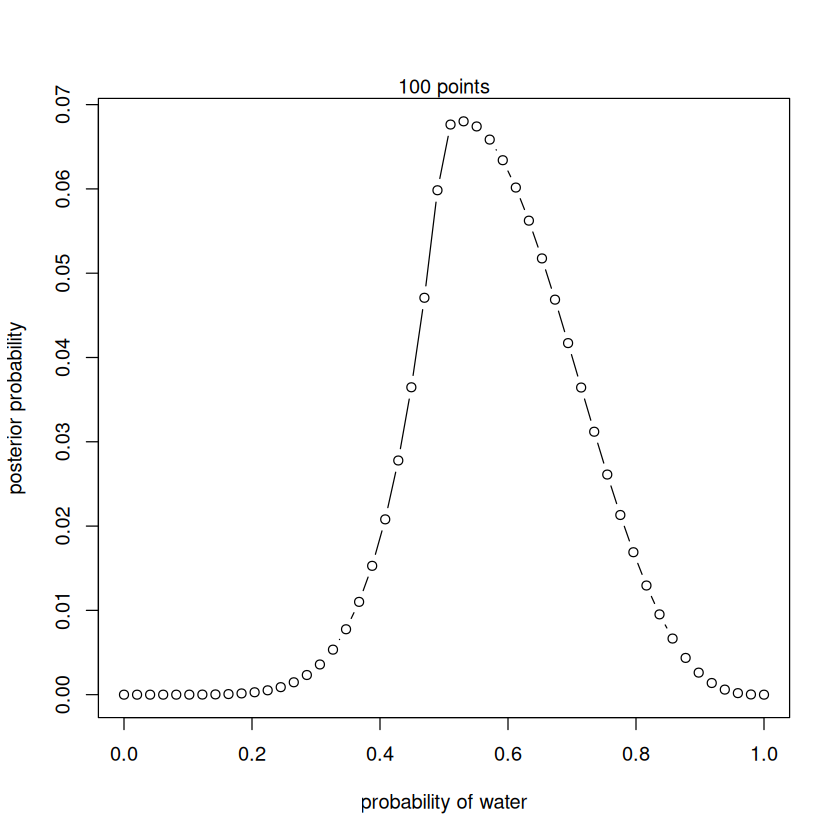

In [ ]:
#define grid
p_grid <- seq(from=0, to=1, length.out=50)

#define prior
# prior <- rep(1, 50)
# prior <- ifelse(p_grid < 0.5, 0, 1)
prior <- exp(-5*abs(p_grid - 0.5))

#compute likelihood at each value in grid
likelihood <- dbinom(6, size=9, prob=p_grid)

#compute product of likelihood and prior
unstd.posterior <- likelihood * prior

#standardize the posterior, so it sums to 1
posterior <- unstd.posterior/sum(unstd.posterior)

par(bg="white")
plot(p_grid, posterior, type="b",
    xlab="probability of water", ylab="posterior probability")
mtext("50 points")

### Quadratic Approximation

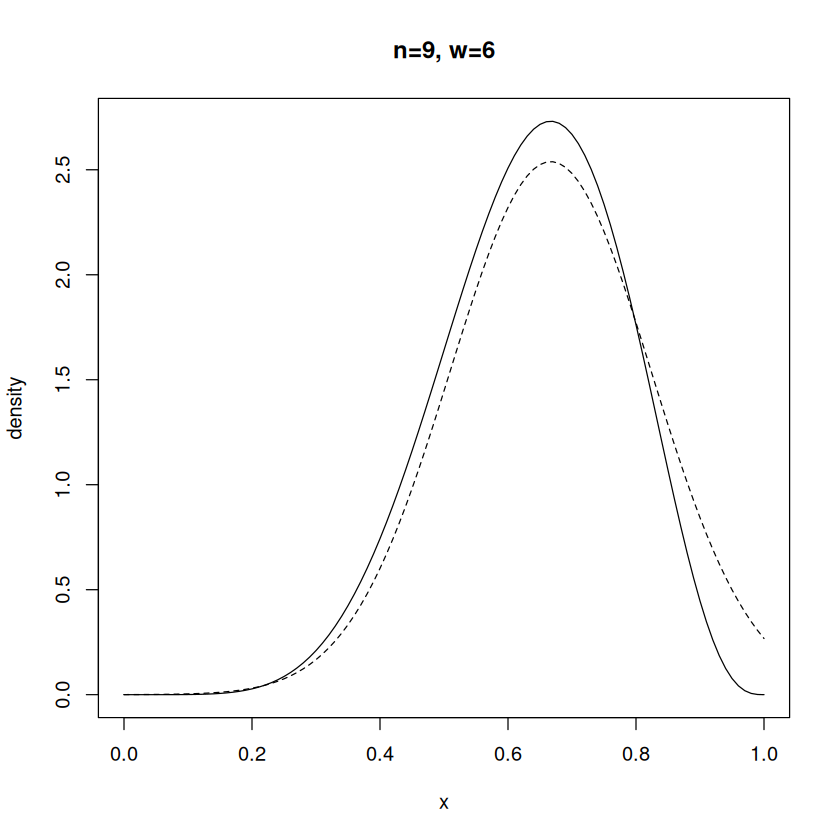

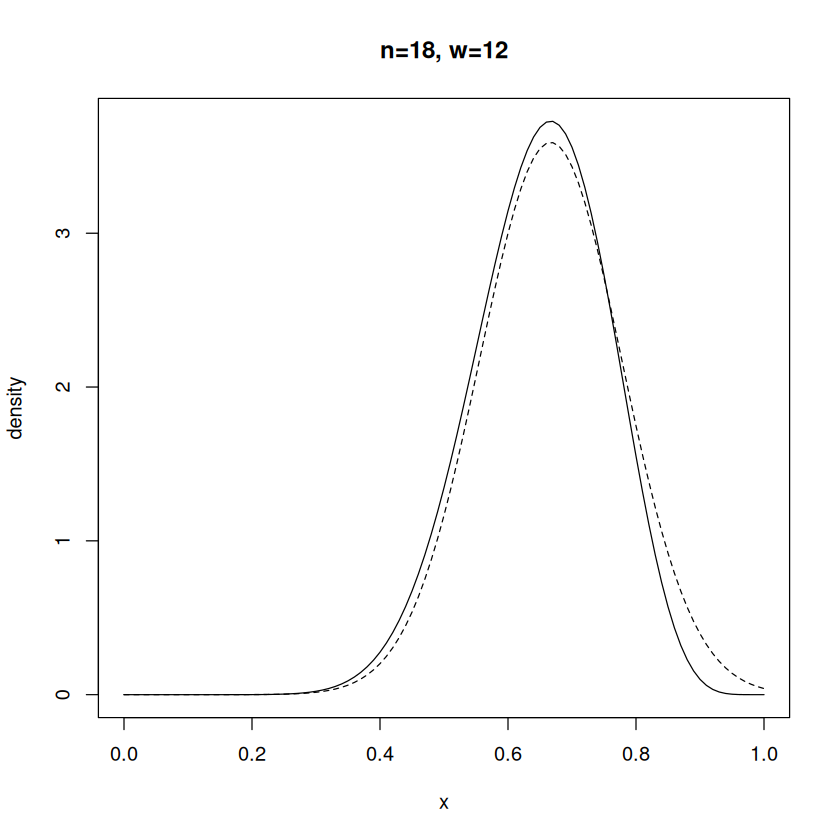

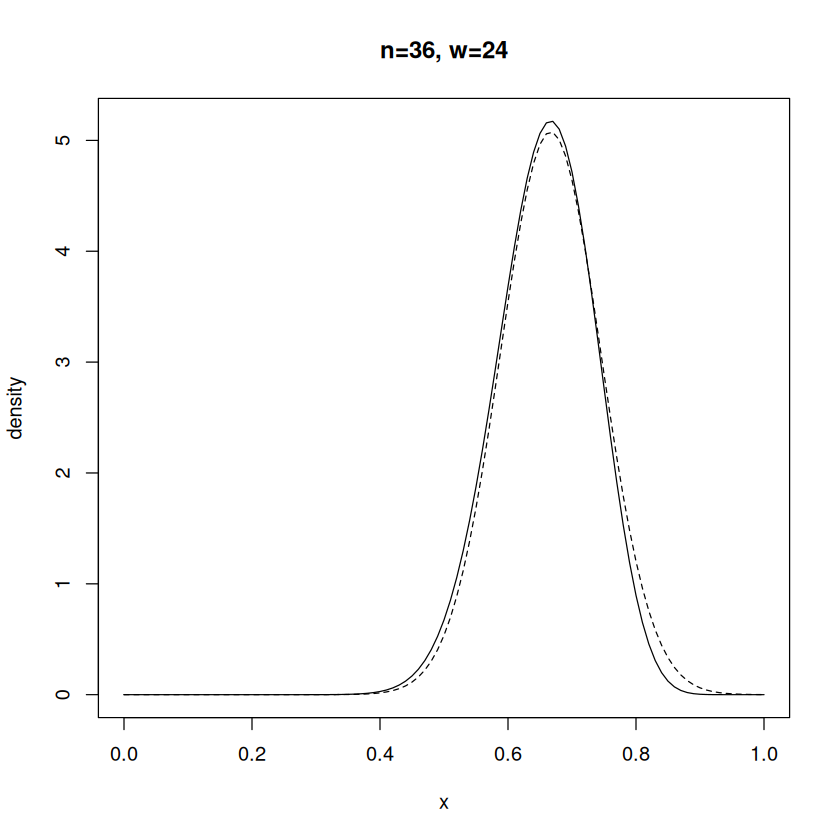

In [5]:
library(rethinking)

n_values <- c(9, 18, 36)

for (n in n_values) {
    w <- n * 2/3

    globe.qa <- map(
        alist(
            w ~ dbinom(n, p),   # binomial likelihood
            p ~ dunif(0, 1)     # uniform prior 
        ),
        data = list(w=w, n=n),
        start = list(p=0.5)
    )

    mu <- coef(globe.qa)["p"]
    sigma <- sqrt(diag(vcov(globe.qa)))["p"]

    # analytical calculation
    curve(dbeta(x, w+1, n-w+1), from=0, to=1,
        main=paste0("n=", n, ", w=", w), ylab="density")

    # quadratic approximation
    curve(dnorm(x, mu, sigma), lty=2, add=TRUE)
}

### Exercises

#### A02
Suppose the globe tossing data had turned out to be 3 water and 11 land. Construct the posterior distribution. Then using the posterior distribution, compute the posterior predictive distribution for the next 5 tosses of the same globe.

In [167]:
p_samples <- rbeta(1e4, 3+1, 11+1)
W_sim <- rbinom(1e4, size=5, p=p_samples)

In [168]:
table(W_sim)

W_sim
   0    1    2    3    4    5 
2797 3458 2404 1036  270   35 

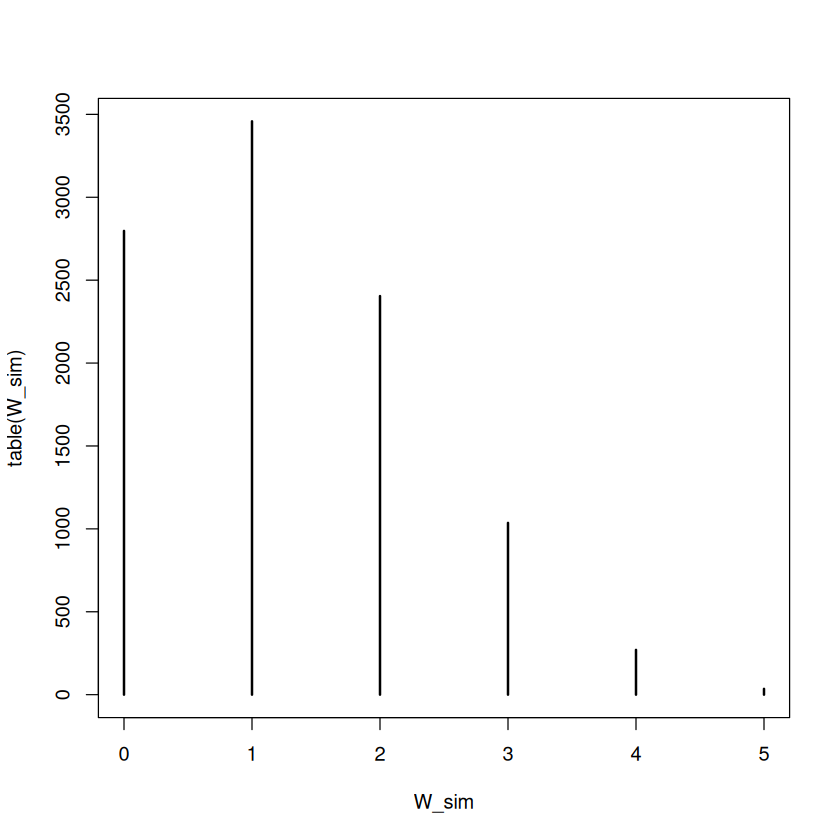

In [169]:
plot(table(W_sim))

#### 2M1

Recall the globe tossing model from the chapter. Compute and plot the grid approximate posterior distribution for each of the following sets of observations. In each case, assume an uniform prior for $p$.

(1) W, W, W \
(2) W, W, W, L \
(3) L, W, W, L, W, W, W

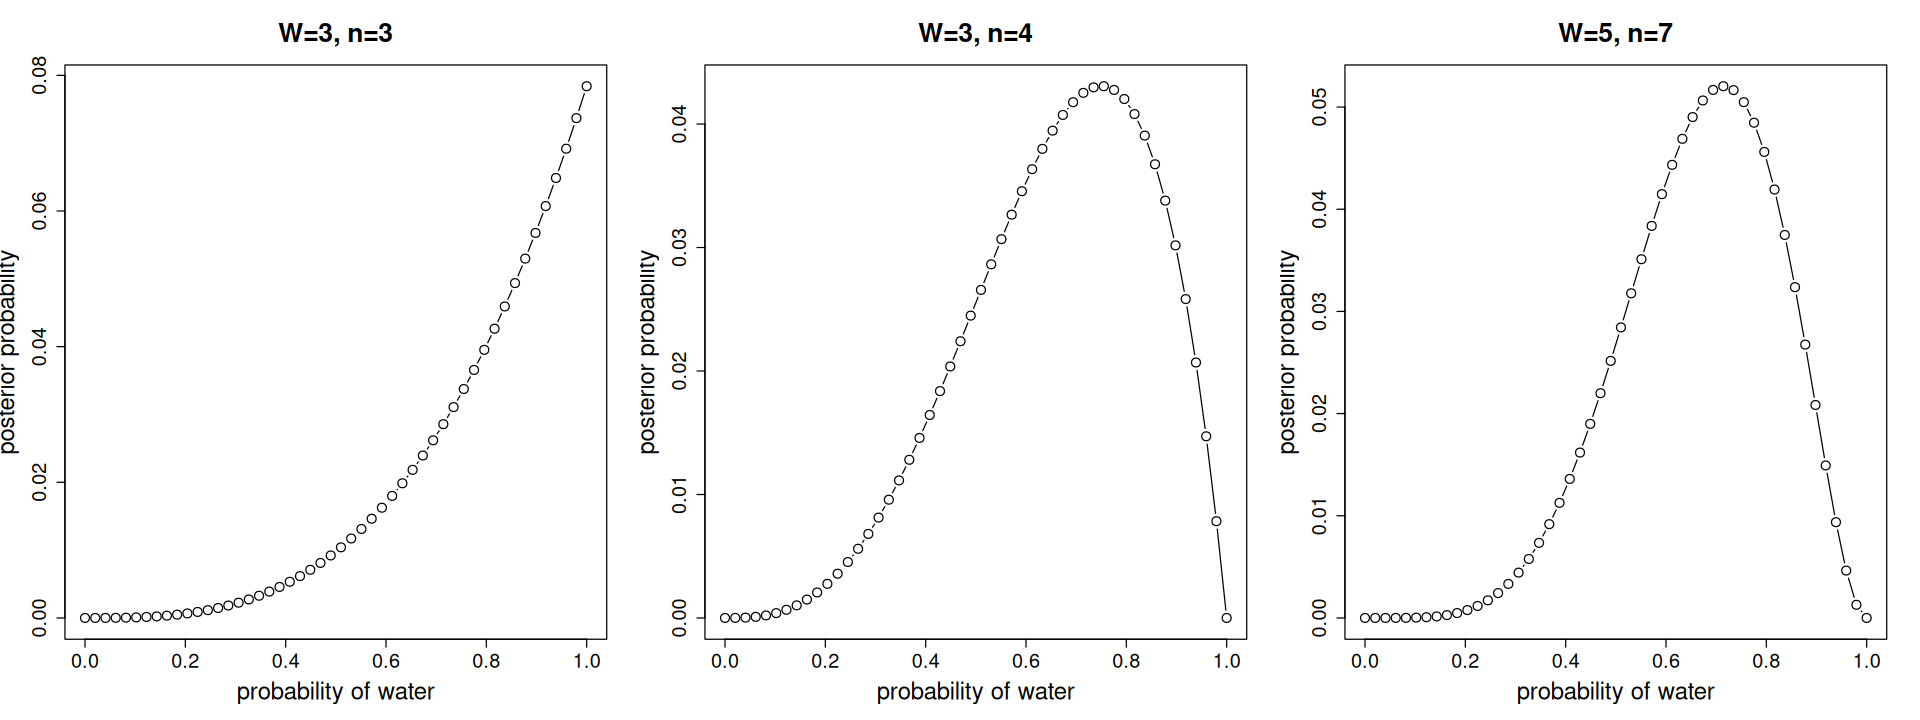

In [ ]:
p_grid <- seq(from=0, to=1, length.out=50)
prior <- rep(1, 50)

Ws <- c(3, 3, 5)
size <- c(3, 4, 7)

# ------ plot configs
options(repr.plot.width = 16, repr.plot.height = 6)
par(mfrow=c(1,3), cex.axis=1.5, cex.lab=1.8, cex.main=2)
# ------

for (i in seq_len(3)) {
    likelihood <- dbinom(Ws[i], size[i], p_grid)
    unstd.posterior <- likelihood * prior
    posterior <- unstd.posterior/sum(unstd.posterior)

    plot(p_grid, posterior, type="b", cex=1.5,
        main=paste0("W=", Ws[i], ", n=", size[i]),
        xlab="probability of water", ylab="posterior probability")
}

#### 2M2

Now assume a prior for $p$ that is equal in zero when $p < 0.5$ and is a positive constant when $p\ge0.5$. Again compute and plot the grid approximate posterior distribution for each of the sets of observations in the problem just above.

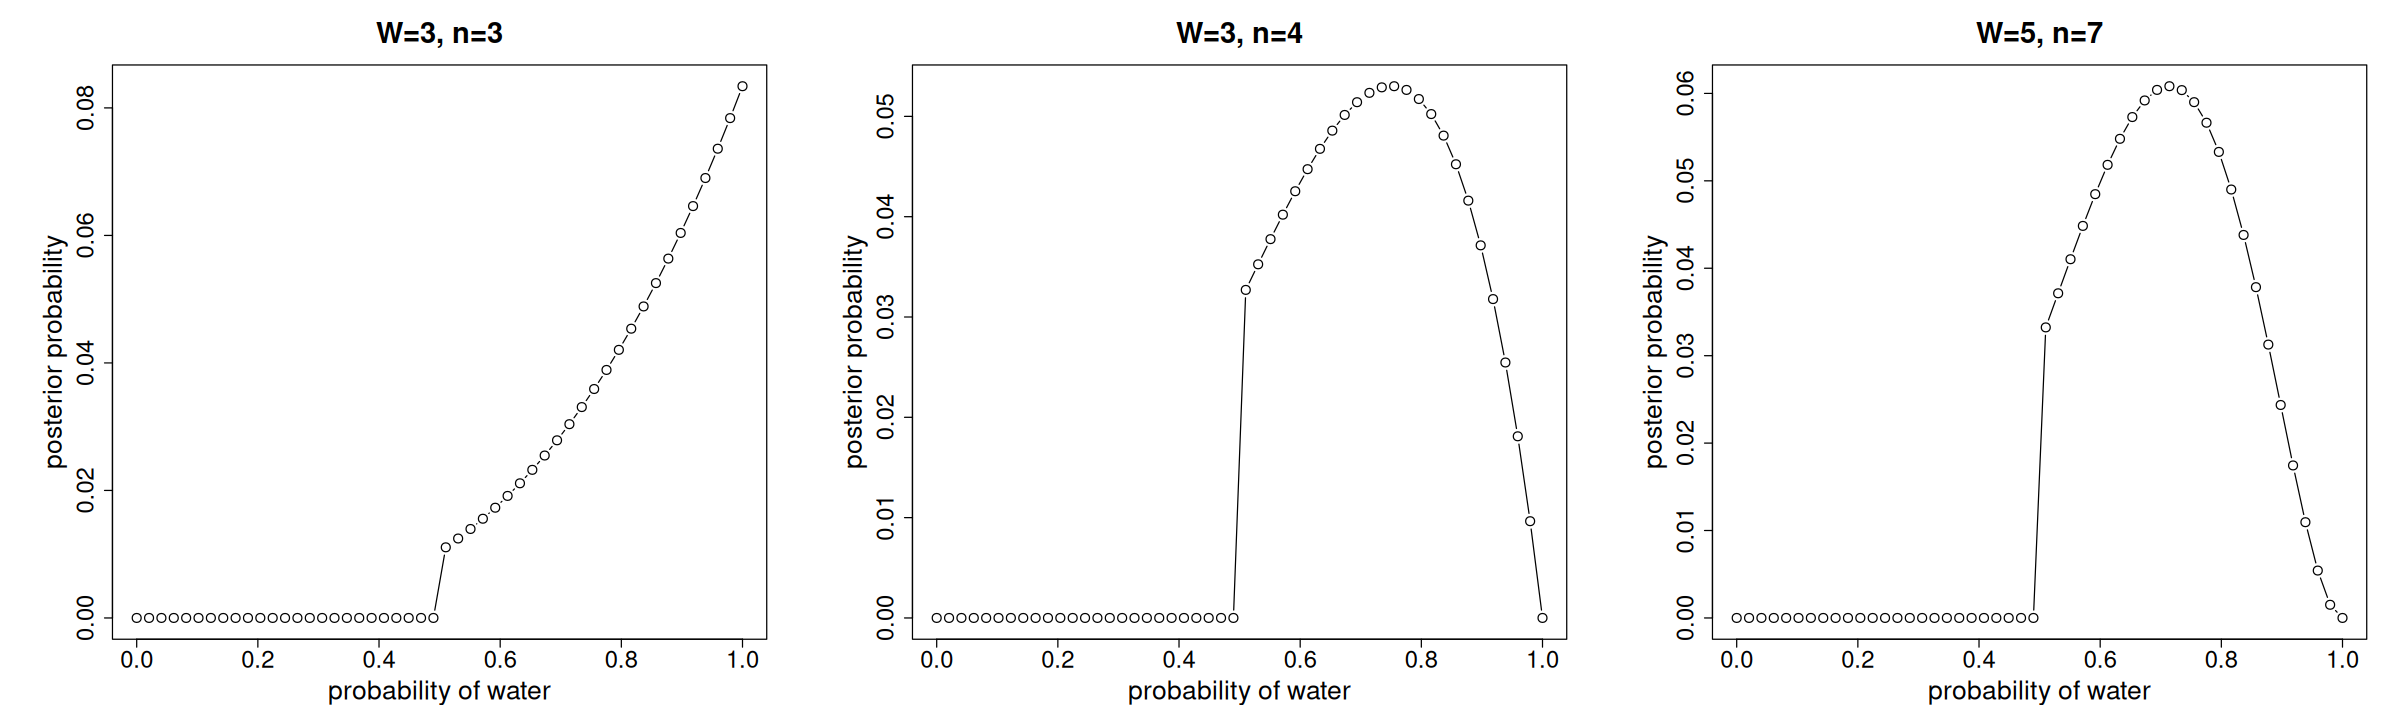

In [264]:
p_grid <- seq(from=0, to=1, length.out=50)
prior <- ifelse(p_grid < 0.5, 0, 1)

Ws <- c(3, 3, 5)
sizes <- c(3, 4, 7)

# ------ plot configs
options(repr.plot.width = 20, repr.plot.height = 6)
par(mfrow=c(1,3), cex.axis=1.8, cex.lab=2, cex.main=2.2,
    mar=c(5, 7, 4, 2) + 0.1)
# ------

for (i in seq_len(3)) {
    likelihood <- dbinom(Ws[i], sizes[i], prob=p_grid)
    unstd.posterior <- likelihood * prior
    posterior <- unstd.posterior/sum(unstd.posterior)

    plot(p_grid, posterior, type="b", cex=1.5,
        main=paste0("W=", Ws[i], ", n=", size[i]),
        xlab="probability of water", ylab="posterior probability")
}

#### 2M3

Suppose there are two globes, one for Earth and one for Mars. The Earth globe is 70% covered in water. The Mars globe is 100% land. Further suppose that one of these globes—you don't know which—was tossed in he air and produced a "land" observation. Assume that each globe was equally likely to be tossed. Show that the posterior probability that the globe was the Earth, conditional on seeing "land" (Pr(Earth|land)), is 0.23.

In [1]:
likelihood <- c(0.3, 1)
prior <- c(0.5, 0.5)
unstd.posterior <- likelihood * prior
posterior <- unstd.posterior/sum(unstd.posterior)

posterior

[1] 0.2307692 0.7692308

#### 2M4

Suppose you have a deck with only three cards. Each card has two sides, and each side is either black or white. One card has two black sides. The second card has ne black and one white side. The third card has two white sides. Now suppose all three cards are placedin a bag and shuffled. Someone reaches into the bag and pulls out a card and places it flat on a table. A black side is shown facing up, but you don't know the color of the side facing down. Show that the probability that the other side is also back is 2/3. Use the counting method (Second 2 of the chapter) to approach this problem. This means counting up the ways that each card could produce the observed data (a black side facing up on the table). 

In [2]:
2/3

[1] 0.6666667

In [23]:
likelihood <- c(2, 1, 0)
likelihood/sum(likelihood)

[1] 0.6666667 0.3333333 0.0000000

#### 2M5

Now suppose that there are four cards: B/B, B/W, W/W, and another B/B. Again suppose a card is drawn from the bag and a black side appears face up. Again calculate the prbability that the other side is black. 

In [22]:
likelihood <- c(2, 1, 0, 2)
4/sum(likelihood)

[1] 0.8

#### 2M6

Imagine that black ink is heavy, and so cards with black sides are heavier than cards with white sides. As a result, it's less likely that a card with black sides is pulled from the bag. So again assume there are three cards: B/B, B/W, W/W. After experimenting a number of times, you conclude that for every way to pull the B/B card from the bag, there are 2 ways to pull B/W card and 3 way to bull the W/W card. Again suppose that a card is pulled and a black side appears face up. Show that the probability the other side is balck is now 0.5. Use the couting method, as before. 

In [ ]:
likelihood <- c(2, 1, 0)
prior <- c(1, 2, 3)
unstd.posterior <- likelihood * prior
posterior <- unstd.posterior/sum(unstd.posterior)

posterior

[1] 0.5 0.5 0.0

#### 2M7

Assume again the original card problem, with a singla card showing a black side face up. Before looking at the other side, we draw another card from the bag and lay it face up the table. The face that is shown on the new card is white. Show that the probability that the first card, the one showing a black side, has black n its other side is now 0.75. Use the counting method, if you can. Hint: Treat this like the sequences of the globe tosses, counting all the ways to see each observation, for each possible first card.

In [44]:
first <- c(2, 1, 0)
second <- c(3, 2, 1)
ways <- first * second
ways/sum(ways)

[1] 0.75 0.25 0.00

#### 2H1

Suppose there are two species of panda bear. Both are equally common in the wild and live in the same place. They look exactly alike and eat the same food, and there is yet no genetic assay capable of telling them apart. They differ hwever in their family sizes. Species A gives birth to twins 10% of the time, otherwise birthing a single infant. Species B births twins 20% of the time, otherwise birthing singleton infants. Assume these numbers are known in certainty, from many years of field research.

Now suppose you are managing a captive panda breeding program. You have a new female panda of unknown species, and she has just given birth to twins. What is the probability that her next birth will also be twins?

In [51]:
prior <- c(0.5, 0.5)
p_twins <- c(0.1, 0.2)

posterior <- p_twins * prior/sum(p_twins * prior)
sum(p_twins * posterior)

[1] 0.1666667

#### 2H2
Recall all the facts from the problem above. Now compute the probability that the panda we have is from species A, assuming we have observed only the first birth and that it was twins.

In [54]:
prior <- c(0.5, 0.5)
first <- c(0.1, 0.2)

unstd.posterior <- prior * first
posterior <- unstd.posterior/sum(unstd.posterior)

posterior[1]

[1] 0.3333333

#### 2H3
Continuing from the previous problem, suppose the same panda mother has a second birth and that it is not twins, but a singleton infant. Compute the posterior probability that this panda is species A. 

In [56]:
prior <- c(0.5, 0.5)
first <- c(0.1, 0.2)
second <- c(0.9, 0.8)

likelihood <- first * second
unstd.posterior <- likelihood * prior
posterior <- unstd.posterior/sum(unstd.posterior)

posterior[1]

[1] 0.36

#### 2H4

A common boast of Bayesian statisticians is that Bayesian inference makes it easy to use all of the data, even if the data are of different types.

So suppose now that a veterinarian comes along who has a new genetic test that she claims can identify the species of out mother panda. But the test, like all tests, is imperfect. This is the information you have about the test:
- The probability it correctly identifies a species A panda is 0.8. 
- The probability it correctly identifies a species B panda is 0.65.

The vet administers the test to your panda and tells you that the test is positive for species A. First ignore your previous information from the births and compute the posterior probability that your panda is species A. Then redo your calculation, now using the birth data as well.

In [72]:
likelihood.test <- c(0.8, 0.35)
posterior1 <- likelihood.test/sum(likelihood.test)

posterior1[1]

[1] 0.6956522

In [73]:
likelihood.births <- c(0.1, 0.2) * c(0.9, 0.8)

unstd.post <- posterior1 * likelihood.births
posterior2 <- unstd.post/sum(unstd.post)

posterior2[1]

[1] 0.5625